Precomputing transition matrices...
Iteration 0: Evaluating Policy...
Iteration 0: Improving Policy...
Iteration 1: Evaluating Policy...
Iteration 1: Improving Policy...
Iteration 2: Evaluating Policy...
Iteration 2: Improving Policy...
Iteration 3: Evaluating Policy...
Iteration 3: Improving Policy...
Iteration 4: Evaluating Policy...
Iteration 4: Improving Policy...


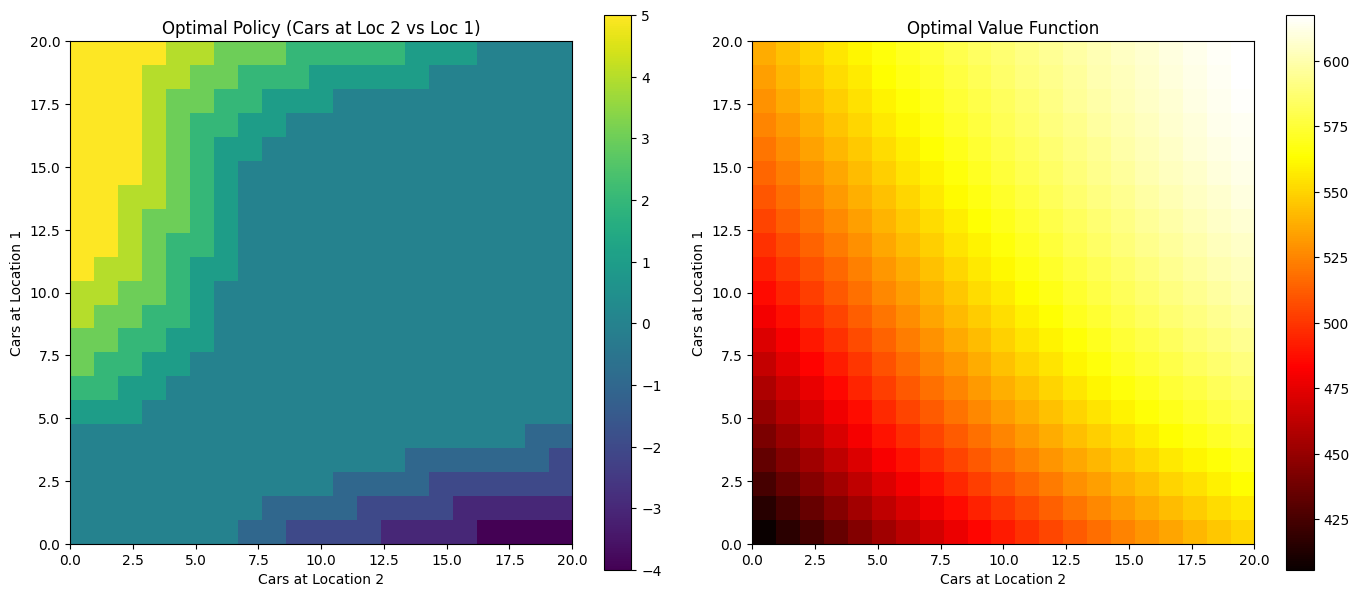

In [1]:
#jack's car rental problem

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# Problem parameters
MAX_CARS = 20
MAX_MOVE = 5
RENT_REWARD = 10
MOVE_COST = 2
DISCOUNT = 0.9

# Poisson expectations
RENTAL_REQUESTS = [3, 4]
RETURNS = [3, 2]

# Precompute Poisson probabilities up to a practical upper bound
POISSON_UPPER_BOUND = 11

poisson_cache = {}
def get_poisson_prob(n, lam):
    key = (n, lam)
    if key not in poisson_cache:
        poisson_cache[key] = poisson.pmf(n, lam)
    return poisson_cache[key]

# Precompute single-location expected rewards and transition probabilities overnight
def precompute_transitions(lambda_rent, lambda_ret):
    # P_loc[initial_cars, next_cars] -> transition prob
    P = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    # R_loc[initial_cars] -> expected rental reward
    R = np.zeros(MAX_CARS + 1)

    for cars in range(MAX_CARS + 1):
        for req in range(POISSON_UPPER_BOUND):
            prob_req = get_poisson_prob(req, lambda_rent)
            actual_rent = min(cars, req)
            R[cars] += prob_req * actual_rent * RENT_REWARD

            for ret in range(POISSON_UPPER_BOUND):
                prob_ret = get_poisson_prob(ret, lambda_ret)
                next_cars = min(cars - actual_rent + ret, MAX_CARS)
                P[cars, next_cars] += prob_req * prob_ret
    return P, R

print("Precomputing transition matrices...")
P1, R1 = precompute_transitions(RENTAL_REQUESTS[0], RETURNS[0])
P2, R2 = precompute_transitions(RENTAL_REQUESTS[1], RETURNS[1])

# Initialize state value function and policy
V = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
policy = np.zeros((MAX_CARS + 1, MAX_CARS + 1), dtype=int)
actions = np.arange(-MAX_MOVE, MAX_MOVE + 1)

def expected_return(state, action, state_value):
    """
    Computes expected return using the precomputed 1D state dynamics.
    """
    cost = MOVE_COST * abs(action)

    # Number of cars at each location after the overnight move
    cars_at_1 = int(min(state[0] - action, MAX_CARS))
    cars_at_2 = int(min(state[1] + action, MAX_CARS))

    # Base reward is the expected rentals at both locations minus the move cost
    expected_val = R1[cars_at_1] + R2[cars_at_2] - cost

    # The distribution of next states is the outer product of the transitions
    next_state_probs = np.outer(P1[cars_at_1], P2[cars_at_2])

    # Expected discounted future value
    expected_val += DISCOUNT * np.sum(next_state_probs * state_value)

    return expected_val

# Policy Iteration
policy_stable = False
iteration = 0

while not policy_stable:
    print(f"Iteration {iteration}: Evaluating Policy...")
    while True:
        delta = 0
        new_V = np.copy(V)
        for i in range(MAX_CARS + 1):
            for j in range(MAX_CARS + 1):
                v = V[i, j]
                action = policy[i, j]
                new_V[i, j] = expected_return((i, j), action, V)
                delta = max(delta, abs(v - new_V[i, j]))
        V = new_V
        if delta < 0.1:
            break

    print(f"Iteration {iteration}: Improving Policy...")
    policy_stable = True
    for i in range(MAX_CARS + 1):
        for j in range(MAX_CARS + 1):
            old_action = policy[i, j]

            # Validate allowable moves based on actual cars available at the beginning of the night
            valid_actions = [a for a in actions if -j <= a <= i]

            action_values = []
            for action in valid_actions:
                action_values.append(expected_return((i, j), action, V))

            best_action = valid_actions[np.argmax(action_values)]
            policy[i, j] = best_action

            if old_action != best_action:
                policy_stable = False

    iteration += 1

# Plotting results
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plot policy
im1 = ax[0].imshow(policy, cmap='viridis', origin='lower', extent=[0, 20, 0, 20])
ax[0].set_title('Optimal Policy (Cars at Loc 2 vs Loc 1)')
ax[0].set_xlabel('Cars at Location 2')
ax[0].set_ylabel('Cars at Location 1')
fig.colorbar(im1, ax=ax[0])

# Plot Value Function
im2 = ax[1].imshow(V, cmap='hot', origin='lower', extent=[0, 20, 0, 20])
ax[1].set_title('Optimal Value Function')
ax[1].set_xlabel('Cars at Location 2')
ax[1].set_ylabel('Cars at Location 1')
fig.colorbar(im2, ax=ax[1])

plt.tight_layout()
plt.show()